# Fraud Detection — Exploratory Data Analysis

**Question:** what distinguishes fraudulent transactions from legitimate ones?

**Data:** 51,000 raw transactions → 50,000 after cleaning; 4.92% fraud.

## TL;DR
1. **No attribute predicts fraud.** Every segment (type, device, city, payment method, amount, hour, account age) is within ~1 point of 4.92%. No chi-square test passes the Bonferroni threshold, and every effect size is ≈ 0.01.
2. **The apparent "hotspots" are noise.** Chicago looks highest (p = 0.02 vs rest), but a simulation shows that picking the top group gives false alarms 22.6% of the time instead of 5%.
3. **Models confirm it.** Logistic regression and gradient boosting both score **ROC-AUC ≈ 0.50**, the same as a model trained on shuffled labels.
4. **The dataset is very likely synthetic.** Past fraud has zero link to current fraud, and missing values and group sizes are suspiciously even. The labels behave like random coin flips.

**Steps:** 1 Overview → 2 Quality audit → 3 Cleaning → 4 EDA → 5 Deep-dive → 6 Visualization → 7 Statistical tests → 8 Cherry-picking simulation → 9 Baseline models → 10 Conclusion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats


In [2]:
DATA_PATH = Path("Fraud Detection Dataset.csv")   # keep the CSV next to the notebook
db = pd.read_csv(DATA_PATH)

In [3]:
db.describe()

,User_ID,Transaction_Amount,Time_of_Transaction,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Fraudulent
count,51000.000000,48480.000000,48448.000000,51000.000000,51000.000000,51000.000000,51000.000000
mean,3005.110176,2996.249784,11.488400,1.995725,60.033902,7.495588,0.049216
std,1153.121107,5043.932555,6.922954,1.415150,34.384131,4.020080,0.216320
min,1000.000000,5.030000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,2007.000000,1270.552500,5.000000,1.000000,30.000000,4.000000,0.000000
50%,2996.000000,2524.100000,12.000000,2.000000,60.000000,7.000000,0.000000
75%,4006.000000,3787.240000,17.000000,3.000000,90.000000,11.000000,0.000000
max,4999.000000,49997.800000,23.000000,4.000000,119.000000,14.000000,1.000000


## Step 1 — Dataset overview and quality

Check the dataset dimensions, column types, missing values, and target-label balance before starting deeper analysis.

In [4]:
print(f"Rows: {len(db):,} | Columns: {db.shape[1]}")
display(db.head())

overview = pd.DataFrame({
    "data_type": db.dtypes.astype(str),
    "missing_values": db.isna().sum(),
    "missing_percent": (db.isna().mean() * 100).round(2),
})
display(overview)

target_summary = (
    db["Fraudulent"].value_counts()
    .rename(index={0: "Legitimate", 1: "Fraud"})
    .rename_axis("label")
    .to_frame("transactions")
)
target_summary["percent"] = (target_summary["transactions"] / len(db) * 100).round(2)
display(target_summary)

Rows: 51,000 | Columns: 12


,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
0,T1,4174,1292.76,ATM Withdrawal,16.0,Tablet,San Francisco,0,119,13,Debit Card,0
1,T2,4507,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
2,T3,1860,2395.02,ATM Withdrawal,NaN,Mobile,NaN,3,115,9,NaN,0
3,T4,2294,100.10,Bill Payment,15.0,Desktop,Chicago,4,3,4,UPI,0
4,T5,2130,1490.50,POS Payment,19.0,Mobile,San Francisco,2,57,7,Credit Card,0


,data_type,missing_values,missing_percent
Transaction_ID,str,0,0.00
User_ID,int64,0,0.00
Transaction_Amount,float64,2520,4.94
Transaction_Type,str,0,0.00
Time_of_Transaction,float64,2552,5.00
Device_Used,str,2473,4.85
Location,str,2547,4.99
Previous_Fraudulent_Transactions,int64,0,0.00
Account_Age,int64,0,0.00
Number_of_Transactions_Last_24H,int64,0,0.00


,transactions,percent
label,,
Legitimate,48490,95.08
Fraud,2510,4.92


### Step 1 findings
- The raw file has **51,000 rows and 12 columns**.
- 5 columns (`Transaction_Amount`, `Time_of_Transaction`, `Device_Used`, `Location`, `Payment_Method`) are each missing **about 5%** of values. The pattern is very even, which suggests the gaps were added randomly, not caused by a real process.
- `Transaction_Amount` is skewed: mean ≈ 2,996, median ≈ 2,524, max ≈ 49,998, and the standard deviation (5,044) is bigger than the mean. This points to **outliers**.
- Only **4.92%** of transactions are fraud. Because of this **class imbalance**, I compare **fraud rates** between groups, not fraud counts.

## Step 2 — Data quality audit

Find problems only. Fixing happens in Step 3.

In [5]:
# Rows that are 100% identical
print("Fully duplicated rows:", db.duplicated().sum())

# Transaction IDs that appear more than once
print("Duplicated Transaction_IDs:", db["Transaction_ID"].duplicated().sum())

# Look at a few repeated IDs side by side
dup_ids = db.loc[db["Transaction_ID"].duplicated(keep=False), "Transaction_ID"]
display(db[db["Transaction_ID"].isin(dup_ids)].sort_values("Transaction_ID").head(10))

Fully duplicated rows: 881
Duplicated Transaction_IDs: 1000


,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
50688,T1004,4190,2828.74,Bill Payment,21.0,Tablet,Boston,2,97,14,Credit Card,0
1003,T1004,4190,2828.74,Bill Payment,21.0,Tablet,Boston,2,97,14,Credit Card,0
50440,T10075,3686,3700.47,ATM Withdrawal,7.0,Mobile,San Francisco,1,38,10,Net Banking,0
10074,T10075,3686,3700.47,ATM Withdrawal,7.0,Mobile,San Francisco,1,38,10,Net Banking,0
50952,T10076,2798,1775.37,Online Purchase,NaN,Desktop,Seattle,4,33,4,Credit Card,1
10075,T10076,2798,1775.37,Online Purchase,NaN,Desktop,Seattle,4,33,4,Credit Card,1
10192,T10193,1225,NaN,ATM Withdrawal,5.0,Tablet,Los Angeles,1,74,13,UPI,0
50494,T10193,1225,NaN,ATM Withdrawal,5.0,Tablet,Los Angeles,1,74,13,UPI,0
50447,T1031,1475,2498.40,Bill Payment,8.0,Mobile,New York,2,56,13,Credit Card,0
1030,T1031,1475,2498.40,Bill Payment,8.0,Mobile,New York,2,56,13,Credit Card,0


In [6]:
for col in ["Transaction_Type", "Device_Used", "Location", "Payment_Method"]:
    print(f"\n--- {col} ---")
    print(db[col].value_counts(dropna=False))


--- Transaction_Type ---
Transaction_Type
Bill Payment       10340
Bank Transfer      10276
ATM Withdrawal     10164
POS Payment        10126
Online Purchase    10094
Name: count, dtype: int64

--- Device_Used ---
Device_Used
Desktop           15795
Mobile            15614
Tablet            15588
NaN                2473
Unknown Device     1530
Name: count, dtype: int64

--- Location ---
Location
Boston           6149
New York         6110
Seattle          6104
Chicago          6071
Houston          6031
Los Angeles      6012
Miami            5991
San Francisco    5985
NaN              2547
Name: count, dtype: int64

--- Payment_Method ---
Payment_Method
UPI               11887
Debit Card        11802
Net Banking       11666
Credit Card       11646
NaN                2469
Invalid Method     1530
Name: count, dtype: int64


In [7]:
q1 = db["Transaction_Amount"].quantile(0.25)
q3 = db["Transaction_Amount"].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print(f"Q1={q1:.2f}  Q3={q3:.2f}  IQR={iqr:.2f}  upper fence={upper:.2f}")

outliers = db[db["Transaction_Amount"] > upper]
print("Outlier rows:", len(outliers))
print("Fraud rate among outliers:", round(outliers["Fraudulent"].mean() * 100, 2), "%")
print("Fraud rate overall:       ", round(db["Fraudulent"].mean() * 100, 2), "%")

Q1=1270.55  Q3=3787.24  IQR=2516.69  upper fence=7562.27
Outlier rows: 508
Fraud rate among outliers: 6.3 %
Fraud rate overall:        4.92 %


In [8]:
print("Hours outside 0–23:", (~db["Time_of_Transaction"].dropna().between(0, 23)).sum())
print("Non-positive amounts:", (db["Transaction_Amount"] <= 0).sum())
print("Account_Age range:", db["Account_Age"].min(), "to", db["Account_Age"].max())

Hours outside 0–23: 0
Non-positive amounts: 0
Account_Age range: 1 to 119


In [9]:
# Calculate the data-quality summary from the original dataset.
duplicate_rows = int(db.duplicated().sum())
duplicate_id_rows = int(db["Transaction_ID"].duplicated().sum())
duplicate_id_groups = db.loc[
    db["Transaction_ID"].duplicated(keep=False)
].groupby("Transaction_ID", dropna=False)
conflicting_id_groups = sum(
    group.drop_duplicates().shape[0] > 1
    for _, group in duplicate_id_groups
)

unknown_device = db["Device_Used"].eq("Unknown Device")
invalid_method = db["Payment_Method"].eq("Invalid Method")
both_placeholders = int((unknown_device & invalid_method).sum())

q1 = db["Transaction_Amount"].quantile(0.25)
q3 = db["Transaction_Amount"].quantile(0.75)
upper_fence = q3 + 1.5 * (q3 - q1)
amount_outliers = db.loc[db["Transaction_Amount"] > upper_fence]

missing_counts = db.isna().sum()
missing_summary = "; ".join(
    f"{column}: {int(count):,}"
    for column, count in missing_counts.items()
    if count > 0
)

data_quality_issues = pd.DataFrame([
    {
        "Issue": "Exact duplicate rows",
        "Column": "All columns",
        "Rows affected": f"{duplicate_rows:,} duplicate copies",
        "Proposed fix": "Verify, then remove exact copies from the analysis data; keep the raw data unchanged.",
    },
    {
        "Issue": "Repeated transaction IDs",
        "Column": "Transaction_ID",
        "Rows affected": f"{duplicate_id_rows:,} repeated-ID rows; {conflicting_id_groups:,} ID groups contain differing rows",
        "Proposed fix": f"All {conflicting_id_groups} conflicting groups differ only by a blank/placeholder → keep one copy per ID (the most complete).",
    },
    {
        "Issue": "Placeholder categories",
        "Column": "Device_Used, Payment_Method",
        "Rows affected": f"Unknown Device: {int(unknown_device.sum()):,}; Invalid Method: {int(invalid_method.sum()):,}; both on same rows: {both_placeholders:,}",
        "Proposed fix": f"Treat as missing. Only {both_placeholders} rows have both, so the equal counts are a coincidence.",
    },
    {
        "Issue": "Missing values",
        "Column": "Multiple columns",
        "Rows affected": missing_summary,
        "Proposed fix": "Categories → \"Unknown\"; amount → median by transaction type + flag; hour → leave blank.",
    },
    {
        "Issue": "High transaction-amount outliers",
        "Column": "Transaction_Amount",
        "Rows affected": f"{len(amount_outliers):,} above the 1.5×IQR upper fence; {int(amount_outliers['Fraudulent'].sum()):,} fraud cases",
        "Proposed fix": f"Keep unless confirmed data errors: fraud rate is {amount_outliers['Fraudulent'].mean() * 100:.2f}% among outliers vs {db['Fraudulent'].mean() * 100:.2f}% overall.",
    },
])

styled_quality_issues = (
    data_quality_issues.style
    .hide(axis="index")
    .set_caption("Data Quality Review")
    .set_properties(
        **{
            "white-space": "normal",
            "text-align": "left",
            "vertical-align": "top",
            "padding": "10px",
        }
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "18px"),
                ("font-weight", "bold"),
                ("text-align", "left"),
                ("padding", "10px 0"),
            ],
        },
        {
            "selector": "th",
            "props": [
                ("background-color", "#1f4e78"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "left"),
            ],
        },
        {
            "selector": "td",
            "props": [("border-bottom", "1px solid #d9e2f3")],
        },
        {
            "selector": "tbody tr:nth-child(even)",
            "props": [("background-color", "#f3f6fa")],
        },
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("width", "100%"),
                ("table-layout", "fixed"),
            ],
        },
    ])
    .set_properties(subset=["Issue"], **{"font-weight": "bold", "min-width": "180px"})
    .set_properties(subset=["Column"], **{"min-width": "170px"})
    .set_properties(subset=["Rows affected"], **{"min-width": "240px"})
    .set_properties(subset=["Proposed fix"], **{"min-width": "420px"})
)

display(styled_quality_issues)

Issue,Column,Rows affected,Proposed fix
Exact duplicate rows,All columns,881 duplicate copies,"Verify, then remove exact copies from the analysis data; keep the raw data unchanged."
Repeated transaction IDs,Transaction_ID,"1,000 repeated-ID rows; 119 ID groups contain differing rows",All 119 conflicting groups differ only by a blank/placeholder → keep one copy per ID (the most complete).
Placeholder categories,"Device_Used, Payment_Method","Unknown Device: 1,530; Invalid Method: 1,530; both on same rows: 58","Treat as missing. Only 58 rows have both, so the equal counts are a coincidence."
Missing values,Multiple columns,"Transaction_Amount: 2,520; Time_of_Transaction: 2,552; Device_Used: 2,473; Location: 2,547; Payment_Method: 2,469","Categories → ""Unknown""; amount → median by transaction type + flag; hour → leave blank."
High transaction-amount outliers,Transaction_Amount,508 above the 1.5×IQR upper fence; 32 fraud cases,Keep unless confirmed data errors: fraud rate is 6.30% among outliers vs 4.92% overall.


### Step 2 findings
- All 1,000 repeated IDs are in rows 50,000 and above, and the 119 "conflicting" groups differ only by a blank or placeholder. The file looks like it was **copied, then had dirty values injected**, so these are the same transactions.
- Outliers are **kept**: fraud is often the outlier, so deleting them would delete evidence.
- No out-of-range values (hours 0–23, amounts > 0, account age 1–119).

## Step 3 — Data cleaning

Work on a copy (`df`) and keep the raw data (`db`) unchanged.

In [10]:
df = db.copy()

# "Unknown Device" and "Invalid Method" are missing values in disguise
df["Device_Used"] = df["Device_Used"].replace("Unknown Device", np.nan)
df["Payment_Method"] = df["Payment_Method"].replace("Invalid Method", np.nan)

print(df[["Device_Used", "Payment_Method"]].isna().sum())

Device_Used       4003
Payment_Method    3999
dtype: int64


In [11]:
before = len(df)

df["_n_missing"] = df.isna().sum(axis=1)                   # count gaps per row
df = (df.sort_values(["Transaction_ID", "_n_missing"])      # most complete first
        .drop_duplicates(subset="Transaction_ID", keep="first")
        .drop(columns="_n_missing")
        .sort_index())

print(f"Removed {before - len(df):,} duplicate rows → {len(df):,} remain")

Removed 1,000 duplicate rows → 50,000 remain


In [12]:
# Categorical columns: an explicit "Unknown" label is honest and keeps the row
for col in ["Device_Used", "Location", "Payment_Method"]:
    df[col] = df[col].fillna("Unknown")

# Amount: flag it first, then fill with the median *of that transaction type*
df["Amount_Was_Missing"] = df["Transaction_Amount"].isna()
df["Transaction_Amount"] = df["Transaction_Amount"].fillna(
    df.groupby("Transaction_Type")["Transaction_Amount"].transform("median")
)

# Hour: leave as missing; use a nullable integer type
df["Time_of_Transaction"] = df["Time_of_Transaction"].astype("Int64")

df.isna().sum()

Transaction_ID                         0
User_ID                                0
Transaction_Amount                     0
Transaction_Type                       0
Time_of_Transaction                 2500
Device_Used                            0
Location                               0
Previous_Fraudulent_Transactions       0
Account_Age                            0
Number_of_Transactions_Last_24H        0
Payment_Method                         0
Fraudulent                             0
Amount_Was_Missing                     0
dtype: int64

In [13]:
for col in ["Transaction_Type", "Device_Used", "Location", "Payment_Method"]:
    df[col] = df[col].astype("category")
df["Fraudulent"] = df["Fraudulent"].astype(bool)
df.info()

<class 'pandas.DataFrame'>
Index: 50000 entries, 0 to 50997
Data columns (total 13 columns):
 #   Column                            Non-Null Count  Dtype   
---  ------                            --------------  -----   
 0   Transaction_ID                    50000 non-null  str     
 1   User_ID                           50000 non-null  int64   
 2   Transaction_Amount                50000 non-null  float64 
 3   Transaction_Type                  50000 non-null  category
 4   Time_of_Transaction               47500 non-null  Int64   
 5   Device_Used                       50000 non-null  category
 6   Location                          50000 non-null  category
 7   Previous_Fraudulent_Transactions  50000 non-null  int64   
 8   Account_Age                       50000 non-null  int64   
 9   Number_of_Transactions_Last_24H   50000 non-null  int64   
 10  Payment_Method                    50000 non-null  category
 11  Fraudulent                        50000 non-null  bool    
 12  Amount

In [14]:
assert df["Transaction_ID"].is_unique
assert len(df) == 50_000
assert df["Transaction_Amount"].notna().all()
assert not df["Device_Used"].isin(["Unknown Device"]).any()
print("All checks passed ✅")

All checks passed ✅


In [15]:
# Saved right after cleaning. Analysis columns added later
# (Account_Age_Group, Amount_Group, Is_Outlier) are NOT in this file.
df.to_csv("fraud_clean.csv", index=False)

### Cleaning log

| # | Change | Rows affected |
|---|---|---|
| 1 | "Unknown Device" / "Invalid Method" → missing | 1,530 + 1,530 |
| 2 | Removed duplicate `Transaction_ID`s (kept the most complete copy) | 1,000 removed → **50,000 rows** |
| 3 | Missing `Device_Used`, `Location`, `Payment_Method` → "Unknown" | 3,901 / 2,500 / 3,891 |
| 4 | Missing `Transaction_Amount` → median of its transaction type, flagged in `Amount_Was_Missing` | 2,471 |
| 5 | `Time_of_Transaction` left blank (nullable `Int64`) | 2,500 |
| 6 | Categorical columns → `category`, `Fraudulent` → `bool` | all |

**Why these choices?**
- **Hour left blank:** filling 2,500 rows with the median (12) would create a fake spike at noon in any hourly chart.
- **Median, not mean:** the mean is pulled up by the outliers (up to ~50,000); the median is not.
- **Median per transaction type:** different transaction types can have different typical amounts, so a per-type median is a better guess.
- **`Amount_Was_Missing` flag:** lets us check later whether filled-in values affect any result, and keeps the cleaning transparent.

## Step 4 — Exploratory analysis

Main tool: **fraud rate per segment**, compared with the overall rate.

In [16]:
overall_rate = df["Fraudulent"].mean() * 100

def fraud_rate_by(col):
    """Fraud rate (%) and transaction count for each value of `col`."""
    out = (df.groupby(col, observed=True)["Fraudulent"]
             .agg(transactions="size", fraud_cases="sum", fraud_rate="mean"))
    out["fraud_rate"] = (out["fraud_rate"] * 100).round(2)
    out["vs_overall"] = (out["fraud_rate"] - overall_rate).round(2)
    return out.sort_values("fraud_rate", ascending=False)

print(f"Overall fraud rate: {overall_rate:.2f}%")

Overall fraud rate: 4.92%


In [17]:
for col in ["Transaction_Type", "Device_Used", "Location", "Payment_Method"]:
    print(f"\n=== {col} ===")
    display(fraud_rate_by(col))


=== Transaction_Type ===


,transactions,fraud_cases,fraud_rate,vs_overall
Transaction_Type,,,,
Online Purchase,9887,507,5.13,0.21
POS Payment,9932,498,5.01,0.09
Bill Payment,10130,502,4.96,0.04
Bank Transfer,10093,487,4.83,-0.09
ATM Withdrawal,9958,466,4.68,-0.24



=== Device_Used ===


,transactions,fraud_cases,fraud_rate,vs_overall
Device_Used,,,,
Unknown,3901,219,5.61,0.69
Mobile,15297,790,5.16,0.24
Desktop,15509,738,4.76,-0.16
Tablet,15293,713,4.66,-0.26



=== Location ===


,transactions,fraud_cases,fraud_rate,vs_overall
Location,,,,
Chicago,5948,329,5.53,0.61
Los Angeles,5895,304,5.16,0.24
San Francisco,5865,293,5.00,0.08
Boston,6027,301,4.99,0.07
Miami,5869,292,4.98,0.06
Unknown,2500,122,4.88,-0.04
New York,5988,284,4.74,-0.18
Houston,5918,275,4.65,-0.27
Seattle,5990,260,4.34,-0.58



=== Payment_Method ===


,transactions,fraud_cases,fraud_rate,vs_overall
Payment_Method,,,,
UPI,11657,596,5.11,0.19
Credit Card,11407,561,4.92,0.00
Debit Card,11601,570,4.91,-0.01
Net Banking,11444,559,4.88,-0.04
Unknown,3891,174,4.47,-0.45


In [18]:
num_cols = ["Transaction_Amount", "Account_Age",
            "Number_of_Transactions_Last_24H", "Previous_Fraudulent_Transactions"]
display(df.groupby("Fraudulent")[num_cols].agg(["mean", "median"]).T.round(2))

Fraudulent                                 False    True 
Transaction_Amount               mean    2968.22  3078.97
                                 median  2506.26  2506.26
Account_Age                      mean      59.98    60.88
                                 median    60.00    62.00
Number_of_Transactions_Last_24H  mean       7.50     7.43
                                 median     7.00     7.00
Previous_Fraudulent_Transactions mean       2.00     2.00
                                 median     2.00     2.00

In [19]:
df["Account_Age_Group"] = pd.cut(df["Account_Age"], bins=[0, 7, 30, 60, 90, 120],
                                 labels=["≤1 wk", "1 wk–1 mo", "1–2 mo", "2–3 mo", "3+ mo"])
df["Amount_Group"] = pd.qcut(df["Transaction_Amount"], q=5,
                             labels=["Very low", "Low", "Medium", "High", "Very high"])

for col in ["Account_Age_Group", "Amount_Group",
            "Previous_Fraudulent_Transactions", "Time_of_Transaction"]:
    print(f"\n=== {col} ===")
    display(fraud_rate_by(col).sort_index())


=== Account_Age_Group ===


,transactions,fraud_cases,fraud_rate,vs_overall
Account_Age_Group,,,,
≤1 wk,3009,150,4.99,0.07
1 wk–1 mo,9580,443,4.62,-0.30
1–2 mo,12632,608,4.81,-0.11
2–3 mo,12564,642,5.11,0.19
3+ mo,12215,617,5.05,0.13



=== Amount_Group ===


,transactions,fraud_cases,fraud_rate,vs_overall
Amount_Group,,,,
Very low,10000,507,5.07,0.15
Low,10000,474,4.74,-0.18
Medium,10000,495,4.95,0.03
High,10000,504,5.04,0.12
Very high,10000,480,4.80,-0.12



=== Previous_Fraudulent_Transactions ===


,transactions,fraud_cases,fraud_rate,vs_overall
Previous_Fraudulent_Transactions,,,,
0,10078,474,4.70,-0.22
1,9932,505,5.08,0.16
2,10098,508,5.03,0.11
3,9873,492,4.98,0.06
4,10019,481,4.80,-0.12



=== Time_of_Transaction ===


,transactions,fraud_cases,fraud_rate,vs_overall
Time_of_Transaction,,,,
0,2009,92,4.58,-0.34
1,1993,95,4.77,-0.15
2,1966,100,5.09,0.17
3,2017,95,4.71,-0.21
4,1986,96,4.83,-0.09
5,1987,89,4.48,-0.44
6,1962,102,5.20,0.28
7,1946,107,5.50,0.58
8,1988,94,4.73,-0.19


In [20]:
per_user = df.groupby("User_ID").agg(transactions=("Transaction_ID", "size"),
                                     fraud_cases=("Fraudulent", "sum"))
print("Unique users:", len(per_user))
display(per_user.describe().round(2))
display(per_user.sort_values("fraud_cases", ascending=False).head(10))

# Is the worst user (5 frauds) surprising? Under "every transaction is 4.92% fraud,
# independently", simulate the maximum fraud count across all 4,000 users.
p_fraud = df["Fraudulent"].mean()
rng_u = np.random.default_rng(0)
sim_max = np.array([rng_u.binomial(per_user["transactions"].to_numpy(), p_fraud).max()
                    for _ in range(2000)])
observed_max = per_user["fraud_cases"].max()
print(f"Observed max frauds per user: {observed_max}")
print(f"Simulated max under pure chance: median {np.median(sim_max):.0f}, "
      f"P(max >= {observed_max}) = {(sim_max >= observed_max).mean():.2f}")
print("Users with >=1 fraud — observed:", (per_user['fraud_cases'] > 0).sum(),
      "| expected by chance:",
      round((1 - (1 - p_fraud) ** per_user["transactions"]).sum()))

Unique users: 4000


,transactions,fraud_cases
count,4000.00,4000.00
mean,12.50,0.62
std,3.54,0.78
min,2.00,0.00
25%,10.00,0.00
50%,12.00,0.00
75%,15.00,1.00
max,26.00,5.00


,transactions,fraud_cases
User_ID,,
3738,18,5
4614,15,5
2785,7,4
3666,15,4
4650,14,4
4681,17,4
2934,17,4
2271,17,4
1374,14,4


Observed max frauds per user: 5
Simulated max under pure chance: median 5, P(max >= 5) = 0.83
Users with >=1 fraud — observed: 1857 | expected by chance: 1837


### Step 4 findings
- **Every segment is within about ±1 point of the overall 4.92%.** Largest gaps: Location (Chicago 5.53% vs Seattle 4.34%), Device (Unknown 5.61% vs Tablet 4.66%), hour (5.78% at 15:00 and 22:00 vs 4.27% at 21:00).
- **Fraud and legitimate transactions look the same on numbers:** median amount 2,506 vs 2,506, median account age 60 vs 62 days, 7 vs 7 transactions in the last 24h.
- **`Previous_Fraudulent_Transactions` does not predict fraud:** 0 previous frauds → 4.70%, 4 previous frauds → 4.80%. No upward trend.
- **Users:** the worst users have 5 frauds. A simulation where every transaction is fraud with the same 4.92% chance produces a max of 5 or more in **83%** of runs, and predicts 1,837 users with at least one fraud (observed: 1,857). So there are no "repeat-fraud" users beyond chance.
- **Open question:** with ~6,000 rows per city, is a 1-point gap real or random? → tested in Step 5.

## Step 5 — Fraud deep-dive

Do **combinations** of attributes show fraud patterns? And which gaps are real vs random chance?

In [21]:
pivot = df.pivot_table(index="Transaction_Type", columns="Device_Used",
                       values="Fraudulent", aggfunc="mean", observed=True) * 100
counts = df.pivot_table(index="Transaction_Type", columns="Device_Used",
                        values="Fraudulent", aggfunc="size", observed=True)
print("Fraud rate (%)")
display(pivot.round(2))
print("Number of transactions in each cell")
display(counts)

Fraud rate (%)


Device_Used,Desktop,Mobile,Tablet,Unknown
Transaction_Type,,,,
ATM Withdrawal,4.35,4.91,4.60,5.41
Bank Transfer,4.86,4.79,4.64,5.58
Bill Payment,4.43,5.49,4.65,6.03
Online Purchase,4.77,5.45,4.89,6.28
POS Payment,5.39,5.21,4.54,4.69


Number of transactions in each cell


Device_Used,Desktop,Mobile,Tablet,Unknown
Transaction_Type,,,,
ATM Withdrawal,3126,3138,2936,758
Bank Transfer,3129,3071,3123,770
Bill Payment,3093,3117,3057,863
Online Purchase,3080,2974,3069,764
POS Payment,3081,2997,3108,746


In [22]:
def shuffle_test(col, n_shuffles=1000, seed=42):
    """How often does random chance produce a gap at least as big as the real one?"""
    rng = np.random.default_rng(seed)
    rates = df.groupby(col, observed=True)["Fraudulent"].mean() * 100
    real_gap = rates.max() - rates.min()

    fake_gaps = []
    for _ in range(n_shuffles):
        shuffled = pd.Series(rng.permutation(df["Fraudulent"].values), index=df.index)
        r = shuffled.groupby(df[col], observed=True).mean() * 100
        fake_gaps.append(r.max() - r.min())

    p_value = np.mean(np.array(fake_gaps) >= real_gap)
    return round(real_gap, 2), p_value

results = {col: shuffle_test(col) for col in
           ["Transaction_Type", "Device_Used", "Location", "Payment_Method",
            "Account_Age_Group", "Amount_Group", "Time_of_Transaction"]}
display(pd.DataFrame(results, index=["real_gap_pts", "p_value"]).T)

,real_gap_pts,p_value
Transaction_Type,0.45,0.569
Device_Used,0.95,0.038
Location,1.19,0.153
Payment_Method,0.64,0.286
Account_Age_Group,0.49,0.600
Amount_Group,0.33,0.811
Time_of_Transaction,1.52,0.855


In [23]:
# Recompute the IQR fence on the CLEANED data, using only real (non-imputed) amounts.
# (The Step 2 fence was on the raw file, which still had duplicates.)
real_amt = df.loc[~df["Amount_Was_Missing"], "Transaction_Amount"]
q1_c, q3_c = real_amt.quantile([0.25, 0.75])
upper_clean = q3_c + 1.5 * (q3_c - q1_c)
print(f"Cleaned-data upper fence: {upper_clean:.2f} (raw-data fence was {upper:.2f})")

df["Is_Outlier"] = df["Transaction_Amount"] > upper_clean
display(fraud_rate_by("Is_Outlier"))
print(shuffle_test("Is_Outlier"))

Cleaned-data upper fence: 7557.37 (raw-data fence was 7562.27)


,transactions,fraud_cases,fraud_rate,vs_overall
Is_Outlier,,,,
True,500,31,6.20,1.28
False,49500,2429,4.91,-0.01


(np.float64(1.29), np.float64(0.186))


### Step 5 findings
- **Combinations:** the highest cell is Online Purchase + Unknown device (6.28%), but it has only 764 rows. Smaller groups swing more by chance, so the most extreme rates usually appear in the smallest cells.
- **Shuffle test:** only `Device_Used` had p < 0.05 (p = 0.038). But I ran 7 tests, so with the **Bonferroni correction** the threshold is 0.05 / 7 ≈ 0.007, and it does not pass.
- The device gap comes from transactions with **no device recorded** (5.6% fraud vs 4.9% for known devices). This is a **hypothesis to monitor**, not a conclusion.
- **Outliers** (fence recomputed on the cleaned, non-imputed amounts: 7,557): 6.20% vs 4.91%, but p = 0.186 with only 31 fraud cases → not enough evidence.
- **Answer to the manager about Chicago:** "Chicago's 5.53% is only 0.6 points above average, and a gap that size appears by pure chance about 15% of the time (p = 0.15). Extra checks on Chicago would cost money without targeting real fraud. I recommend not changing rules based on location."

## Step 6 — Visualization

In [24]:
sns.set_theme(style="whitegrid")
Path("figures").mkdir(exist_ok=True)

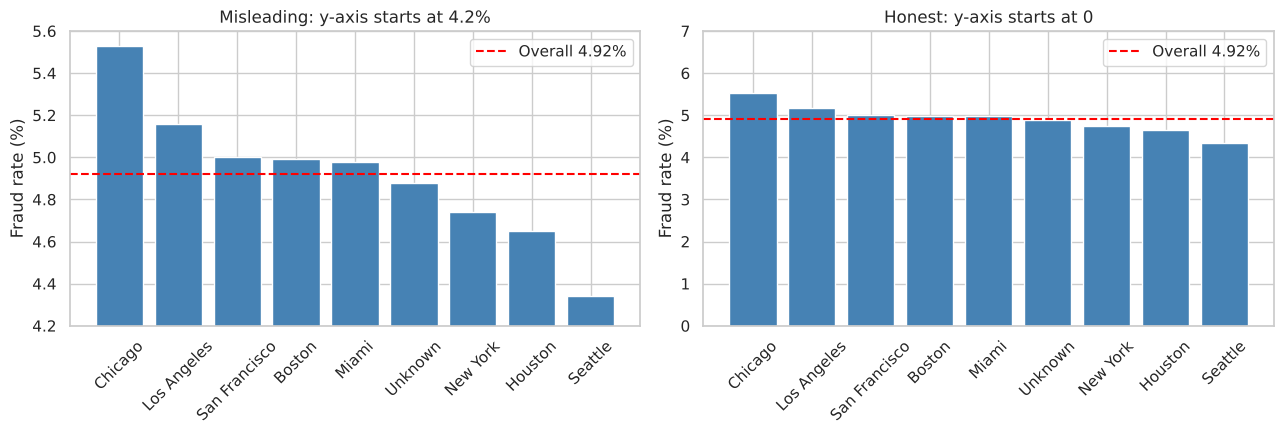

In [25]:
loc = fraud_rate_by("Location")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, title, ylim in [(axes[0], "Misleading: y-axis starts at 4.2%", (4.2, 5.6)),
                        (axes[1], "Honest: y-axis starts at 0", (0, 7))]:
    ax.bar(loc.index.astype(str), loc["fraud_rate"], color="steelblue")
    ax.axhline(overall_rate, color="red", ls="--", label=f"Overall {overall_rate:.2f}%")
    ax.set_ylim(*ylim)
    ax.set_title(title)
    ax.set_ylabel("Fraud rate (%)")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
plt.tight_layout()
plt.savefig("figures/location_misleading_vs_honest.png", dpi=150)
plt.show()

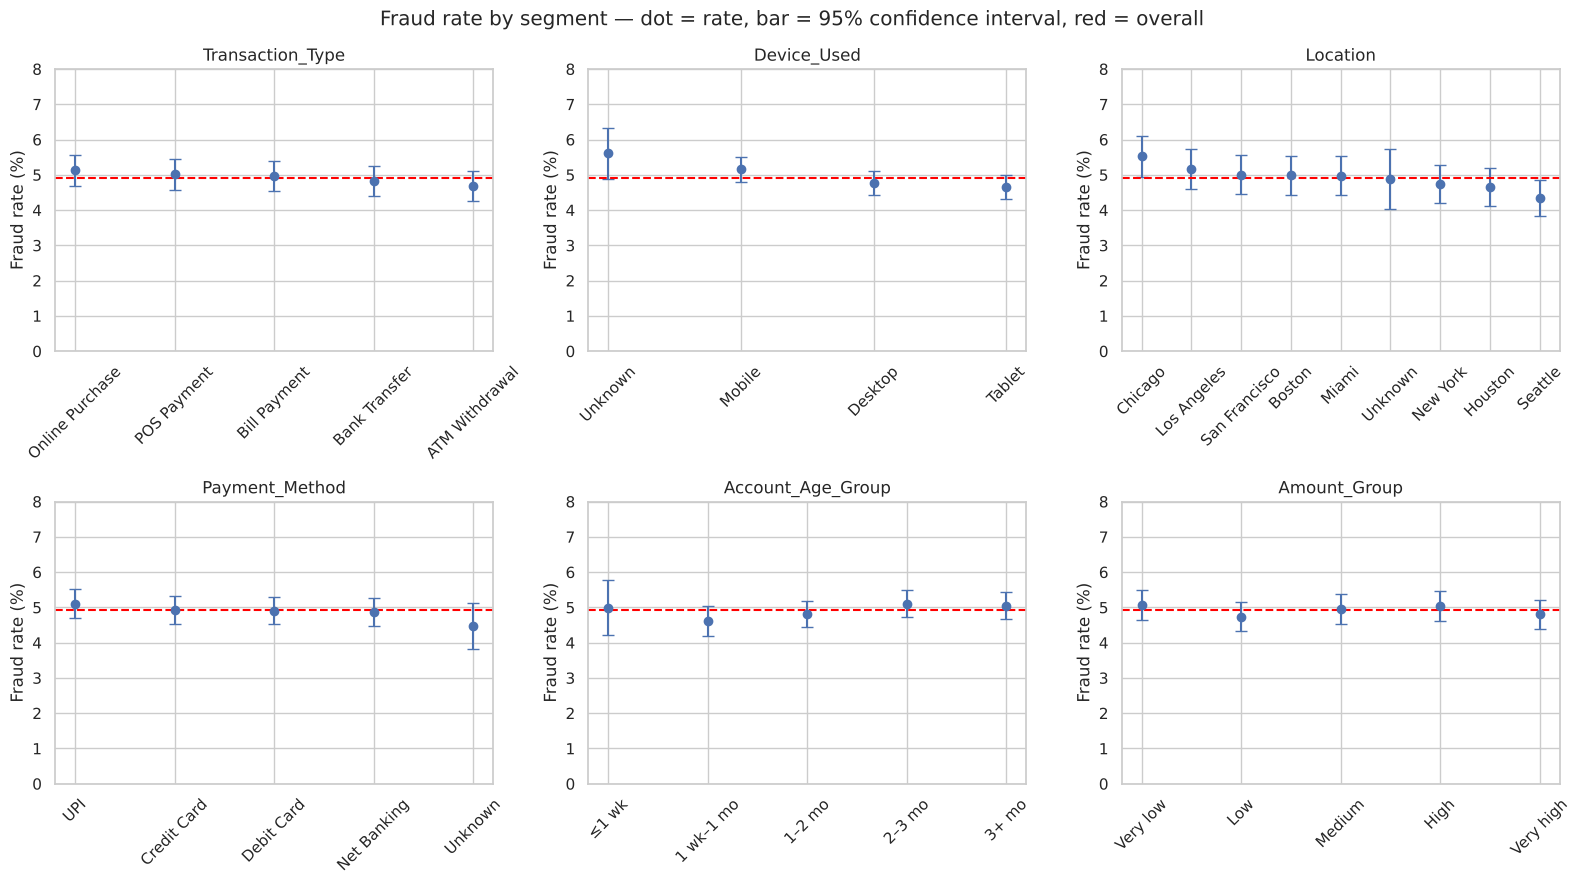

In [26]:
def plot_rate_with_ci(col, ax, sort=True):
    t = fraud_rate_by(col)
    if not sort:
        t = t.sort_index()
    p = t["fraud_rate"] / 100
    ci = 1.96 * np.sqrt(p * (1 - p) / t["transactions"]) * 100   # 95% CI, in % points
    ax.errorbar(t.index.astype(str), t["fraud_rate"], yerr=ci, fmt="o", capsize=4)
    ax.axhline(overall_rate, color="red", ls="--")
    ax.set_ylim(0, 8)
    ax.set_title(col)
    ax.set_ylabel("Fraud rate (%)")
    ax.tick_params(axis="x", rotation=45)

cols = ["Transaction_Type", "Device_Used", "Location",
        "Payment_Method", "Account_Age_Group", "Amount_Group"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, cols):
    plot_rate_with_ci(col, ax, sort=col not in ["Account_Age_Group", "Amount_Group"])
fig.suptitle("Fraud rate by segment — dot = rate, bar = 95% confidence interval, red = overall")
plt.tight_layout()
plt.savefig("figures/fraud_rate_by_segment.png", dpi=150)
plt.show()

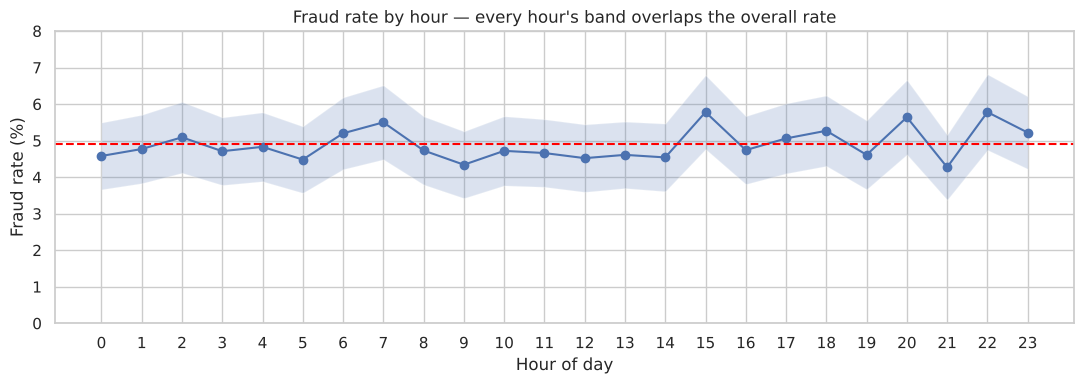

In [27]:
hour = fraud_rate_by("Time_of_Transaction").sort_index()
p = hour["fraud_rate"] / 100
ci = 1.96 * np.sqrt(p * (1 - p) / hour["transactions"]) * 100
x = hour.index.astype(int)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(x, hour["fraud_rate"], marker="o")
ax.fill_between(x, hour["fraud_rate"] - ci, hour["fraud_rate"] + ci, alpha=0.2)
ax.axhline(overall_rate, color="red", ls="--")
ax.set_xticks(range(24))
ax.set_ylim(0, 8)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Fraud rate by hour — every hour's band overlaps the overall rate")
plt.tight_layout()
plt.savefig("figures/fraud_rate_by_hour.png", dpi=150)
plt.show()

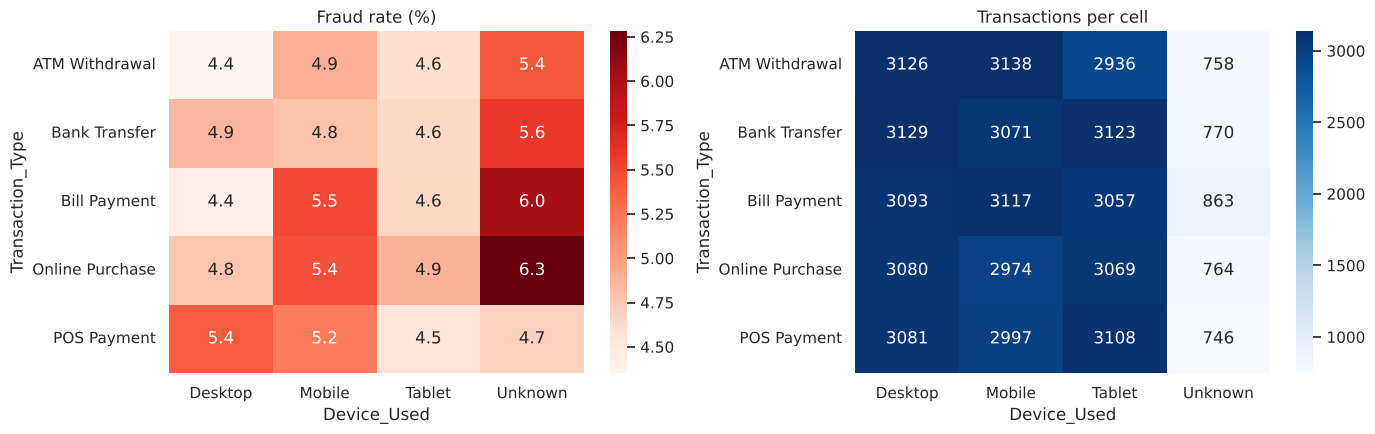

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", ax=axes[0])
axes[0].set_title("Fraud rate (%)")
sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", ax=axes[1])
axes[1].set_title("Transactions per cell")
plt.tight_layout()
plt.savefig("figures/type_x_device_heatmap.png", dpi=150)
plt.show()

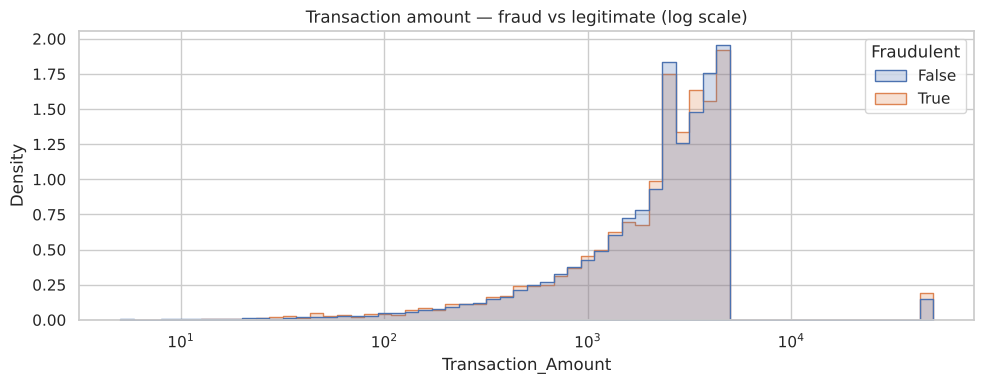

In [29]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=df, x="Transaction_Amount", hue="Fraudulent", stat="density",
             common_norm=False, bins=60, log_scale=True, element="step", ax=ax)
ax.set_title("Transaction amount — fraud vs legitimate (log scale)")
plt.tight_layout()
plt.savefig("figures/amount_distribution.png", dpi=150)
plt.show()

### Step 6 findings
1. **Misleading vs honest chart:** the left chart (y-axis starting at 4.2%) makes Chicago look twice as bad as Seattle. A manager would remember "Chicago is a hotspot" and might spend money on the wrong problem. The honest chart shows that all cities are nearly the same.
2. **Confidence intervals:** out of 33 groups, only 2–3 bars (Chicago, Seattle, Unknown device) barely miss the red line. At 95% confidence, we'd expect 1–2 of 33 to miss by chance, so this matches "mostly noise".
3. **`stat="density"` + `common_norm=False`:** there are ~19× more legitimate transactions than fraud. Without these settings, the fraud curve would be squashed flat at the bottom. With them, each group's curve has the same area, so we compare their *shapes*.
4. **`log_scale=True`:** normal amounts stop sharply at **5,000**, then there is a separate small cluster around **40,000–50,000** (the outliers). On a normal scale everything would be squeezed into the left edge; the log scale spreads it out.
   - The two curves have almost the same shape, so **amount does not separate fraud from legitimate**.
   - The tall bar near **2,500** is partly **created by our cleaning**: ~2,500 missing amounts were filled with the median (~2,506). This is why we kept the `Amount_Was_Missing` flag.
   - The 40k–50k cluster looks like values multiplied ×10, possibly a data-entry error. Worth checking with the data owner.
5. **Best chart for a manager:** the confidence-interval chart (`fraud_rate_by_segment.png`).
   *Caption: "Fraud happens at about 5% in every segment — no device, city, payment method, amount or account age stands out."*

## Step 7 — Statistical testing

The shuffle test (Step 5) answered "could this gap be random chance?" by simulation. Here we use the **standard formal tests** that analysts are expected to know, and check that they agree.

| Question | Data type | Test |
|---|---|---|
| Is fraud rate related to a category? | category vs yes/no | **Chi-square test** |
| Do fraud and legit differ on a number? | number vs yes/no | **t-test** (means) / **Mann-Whitney U** (skewed data) |
| Is group A's fraud rate different from group B's? | two proportions | **Two-proportion z-test** |
| How *big* is the relationship? | — | **Effect size** (Cramér's V, correlation) |

Rule: **p < 0.05** = unlikely to be chance. With many tests, use the **Bonferroni** threshold: 0.05 ÷ number of tests.

In [30]:
# 7.1 Chi-square test: is each category related to fraud?
def chi_square(col):
    table = pd.crosstab(df[col], df["Fraudulent"])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    n = table.to_numpy().sum()
    cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))   # effect size: 0 = none, 1 = perfect
    return {"chi2": round(chi2, 2), "dof": dof, "p_value": round(p, 4),
            "cramers_v": round(cramers_v, 4)}

cat_cols = ["Transaction_Type", "Device_Used", "Location", "Payment_Method",
            "Account_Age_Group", "Amount_Group", "Previous_Fraudulent_Transactions",
            "Time_of_Transaction"]
chi_results = pd.DataFrame({col: chi_square(col) for col in cat_cols}).T

bonferroni = 0.05 / len(cat_cols)
chi_results["significant_0.05"] = chi_results["p_value"] < 0.05
chi_results[f"significant_bonferroni_{bonferroni:.4f}"] = chi_results["p_value"] < bonferroni
display(chi_results.sort_values("p_value"))

,chi2,dof,p_value,cramers_v,significant_0.05,significant_bonferroni_0.0063
Device_Used,9.01,3.0,0.0292,0.0134,True,False
Location,11.29,8.0,0.1856,0.0150,False,False
Account_Age_Group,3.54,4.0,0.4712,0.0084,False,False
Payment_Method,2.63,4.0,0.6218,0.0073,False,False
Transaction_Type,2.55,4.0,0.6351,0.0071,False,False
Previous_Fraudulent_Transactions,2.24,4.0,0.6918,0.0067,False,False
Time_of_Transaction,19.00,23.0,0.7011,0.0200,False,False
Amount_Group,1.81,4.0,0.7709,0.0060,False,False


In [31]:
# 7.2 Numeric columns: do fraud and legitimate transactions differ?
fraud = df[df["Fraudulent"]]
legit = df[~df["Fraudulent"]]

rows = []
for col in num_cols:
    t_stat, t_p = stats.ttest_ind(fraud[col], legit[col], equal_var=False)   # Welch's t-test (means)
    u_stat, u_p = stats.mannwhitneyu(fraud[col], legit[col])                  # rank-based (medians/shape)
    rows.append({"column": col,
                 "fraud_mean": round(fraud[col].mean(), 2),
                 "legit_mean": round(legit[col].mean(), 2),
                 "t_test_p": round(t_p, 4),
                 "mann_whitney_p": round(u_p, 4)})
display(pd.DataFrame(rows).set_index("column"))

,fraud_mean,legit_mean,t_test_p,mann_whitney_p
column,,,,
Transaction_Amount,3078.97,2968.22,0.3263,0.6836
Account_Age,60.88,59.98,0.2047,0.2012
Number_of_Transactions_Last_24H,7.43,7.50,0.3828,0.3818
Previous_Fraudulent_Transactions,2.00,2.00,0.8860,0.8861


In [32]:
# 7.2b Transaction_Amount again — this time WITHOUT the ~2,500 imputed amounts.
# The imputed rows all sit at the per-type median, so they pull both groups' medians
# to the same value (2,506.26) and blur any real difference.
real = df[~df["Amount_Was_Missing"]]
f_amt = real.loc[real["Fraudulent"], "Transaction_Amount"]
l_amt = real.loc[~real["Fraudulent"], "Transaction_Amount"]

print(f"Rows used: {len(real):,} (dropped {df['Amount_Was_Missing'].sum():,} imputed)")
print(f"Median  fraud {f_amt.median():,.2f} | legit {l_amt.median():,.2f}")
print(f"Mean    fraud {f_amt.mean():,.2f} | legit {l_amt.mean():,.2f}")
print(f"t-test p = {stats.ttest_ind(f_amt, l_amt, equal_var=False).pvalue:.4f}")
print(f"Mann-Whitney p = {stats.mannwhitneyu(f_amt, l_amt).pvalue:.4f}")

# Amount quintiles on real amounts only
real_groups = pd.qcut(real["Transaction_Amount"], q=5,
                      labels=["Very low", "Low", "Medium", "High", "Very high"])
tab = real.groupby(real_groups, observed=True)["Fraudulent"].agg(transactions="size", fraud_rate="mean")
tab["fraud_rate"] = (tab["fraud_rate"] * 100).round(2)
display(tab)
chi2, p_q, _, _ = stats.chi2_contingency(pd.crosstab(real_groups, real["Fraudulent"]))
print(f"Chi-square on real-amount quintiles: p = {p_q:.4f}")

# Did imputation itself change anything? Fraud rate among imputed vs real rows
print(fraud_rate_by("Amount_Was_Missing"))

Rows used: 47,529 (dropped 2,471 imputed)
Median  fraud 2,505.75 | legit 2,524.32
Mean    fraud 3,108.13 | legit 2,991.41
t-test p = 0.3257
Mann-Whitney p = 0.6641


,transactions,fraud_rate
Transaction_Amount,,
Very low,9506,5.07
Low,9506,4.77
Medium,9505,5.04
High,9506,4.83
Very high,9506,4.88


Chi-square on real-amount quintiles: p = 0.8379
                    transactions  fraud_cases  fraud_rate  vs_overall
Amount_Was_Missing                                                   
True                        2471          123        4.98        0.06
False                      47529         2337        4.92        0.00


In [33]:
# 7.3 Two-proportion z-test: compare one group against everyone else
def two_proportion_z(mask, label):
    x1, n1 = df.loc[mask, "Fraudulent"].sum(), mask.sum()
    x2, n2 = df.loc[~mask, "Fraudulent"].sum(), (~mask).sum()
    p1, p2 = x1 / n1, x2 / n2
    p_pool = (x1 + x2) / (n1 + n2)
    se = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
    z = (p1 - p2) / se
    p_value = 2 * stats.norm.sf(abs(z))
    return {"group": label, "group_rate_%": round(p1 * 100, 2), "rest_rate_%": round(p2 * 100, 2),
            "diff_pts": round((p1 - p2) * 100, 2), "z": round(z, 2), "p_value": round(p_value, 4)}

z_results = pd.DataFrame([
    two_proportion_z(df["Location"] == "Chicago", "Chicago vs rest"),
    two_proportion_z(df["Location"] == "Seattle", "Seattle vs rest"),
    two_proportion_z(df["Device_Used"] == "Unknown", "Unknown device vs rest"),
    two_proportion_z(df["Is_Outlier"], "Amount outliers vs rest"),
]).set_index("group")
display(z_results)

,group_rate_%,rest_rate_%,diff_pts,z,p_value
group,,,,,
Chicago vs rest,5.53,4.84,0.69,2.32,0.0202
Seattle vs rest,4.34,5.00,-0.66,-2.21,0.0271
Unknown device vs rest,5.61,4.86,0.75,2.09,0.0369
Amount outliers vs rest,6.20,4.91,1.29,1.33,0.1835


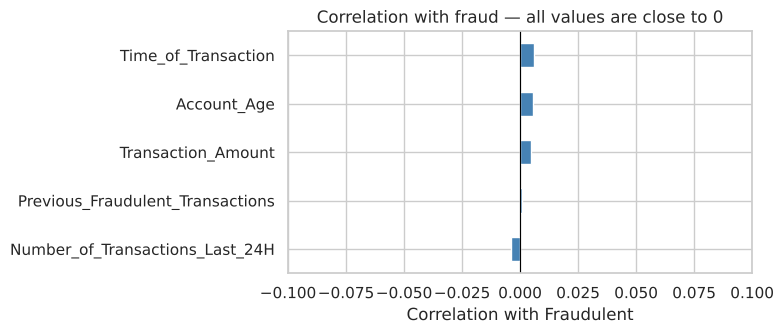

,correlation
Number_of_Transactions_Last_24H,-0.0039
Previous_Fraudulent_Transactions,0.0006
Transaction_Amount,0.0049
Account_Age,0.0057
Time_of_Transaction,0.0060


In [34]:
# 7.4 Correlation of every numeric column with fraud (point-biserial = Pearson with a 0/1 column)
corr_cols = num_cols + ["Time_of_Transaction"]
corr = (df[corr_cols + ["Fraudulent"]].astype(float)
          .corr()["Fraudulent"].drop("Fraudulent").sort_values())

fig, ax = plt.subplots(figsize=(8, 3.5))
corr.plot.barh(ax=ax, color="steelblue")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-0.1, 0.1)
ax.set_xlabel("Correlation with Fraudulent")
ax.set_title("Correlation with fraud — all values are close to 0")
plt.tight_layout()
plt.savefig("figures/correlation_with_fraud.png", dpi=150)
plt.show()
display(corr.round(4).to_frame("correlation"))

### Step 7 findings

**1. Chi-square agrees with the shuffle test.**

| Column | Shuffle p (Step 5) | Chi-square p | Cramér's V |
|---|---|---|---|
| Device_Used | 0.038 | 0.029 | 0.013 |
| Location | 0.153 | 0.186 | 0.015 |
| All others | 0.29 – 0.86 | 0.47 – 0.77 | < 0.01 |

Only `Device_Used` is below 0.05, and **nothing passes the Bonferroni threshold** (0.05 ÷ 8 = 0.0063). Cramér's V is ~0.01 everywhere, where 0 means no relationship and 0.1 would still be "weak". So even the "significant" result is tiny.

**2. Numbers don't differ.** Fraud vs legitimate: t-test and Mann-Whitney p = 0.20 – 0.89 for amount, account age, 24h activity and previous frauds. Every correlation with fraud is between −0.004 and +0.006, which is essentially zero.

**2b. Imputation check.** The identical medians (2,506.26 for both groups) were an artifact of filling 2,471 amounts with the per-type median. Re-running on real amounts only: medians 2,505.75 (fraud) vs 2,524.32 (legit), t-test p = 0.33, Mann-Whitney p = 0.66, chi-square across quintiles p = 0.84. Imputed rows have the same fraud rate as real ones (4.98% vs 4.92%). Conclusion unchanged, and the imputation did not bias it.

**3. ⚠️ The Chicago trap (cherry-picking).** The z-test says *Chicago vs rest: p = 0.02*, which looks significant. But I **chose Chicago because it was the highest** of 8 cities. If you pick the most extreme group after looking at the data and then test it, you will almost always get a small p-value. That's why Seattle (the *lowest*) is "significant" too (p = 0.03). The honest test is the one that looks at **all cities at once**: chi-square p = 0.19 → no evidence. With Bonferroni across the 9 location groups (8 cities + Unknown; 0.05 ÷ 9 = 0.0056), neither passes. Step 8 proves this with a simulation.

**4. Overall conclusion.** None of the available attributes has a meaningful relationship with fraud. The only weak hint is that transactions with **no device recorded** have slightly more fraud (5.6% vs 4.9%, p ≈ 0.03, not significant after correction). Recommendation: **don't build rules on these columns**; collect better signals (e.g. device fingerprint, IP, merchant, time since last transaction) and monitor missing-device transactions.

## Step 8 — Proving the cherry-picking trap

Simulate a world with **no real pattern**: 9 groups × 6,000 transactions (like our 8 cities + Unknown), all with a true 5% fraud rate. Then count how often each method wrongly reports a "significant" difference.

In [35]:
# 8.1 Simulate the cherry-picking trap: pure noise, 9 groups
rng = np.random.default_rng(42)
n_groups, n_per_group, base_rate = 9, 6000, 0.05
n_sims = 1000
labels = np.repeat(np.arange(n_groups), n_per_group)   # same group layout every run

false_positives_naive = 0     # z-test on the max group
false_positives_honest = 0    # chi-square across all groups

for _ in range(n_sims):
    # No real effect: every group has the same true fraud rate
    fraud = rng.random(n_groups * n_per_group) < base_rate

    # Naive approach: find the max group, then z-test it vs the rest
    rates = np.array([fraud[labels == g].mean() for g in range(n_groups)])
    worst = rates.argmax()
    mask = labels == worst
    x1, n1 = fraud[mask].sum(), mask.sum()
    x2, n2 = fraud[~mask].sum(), (~mask).sum()
    p_pool = (x1 + x2) / (n1 + n2)
    se = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
    z = (x1 / n1 - x2 / n2) / se
    p_naive = 2 * stats.norm.sf(abs(z))
    false_positives_naive += (p_naive < 0.05)

    # Honest approach: chi-square across all 9 groups
    table = pd.crosstab(labels, fraud)
    chi2, p_honest, _, _ = stats.chi2_contingency(table)
    false_positives_honest += (p_honest < 0.05)

print(f"Nominal false-positive rate:      5.0%")
print(f"Naive z-test on max group:        {false_positives_naive / n_sims * 100:.1f}%")
print(f"Honest chi-square across all:     {false_positives_honest / n_sims * 100:.1f}%")

Nominal false-positive rate:      5.0%
Naive z-test on max group:        22.6%
Honest chi-square across all:     4.3%


### Step 8 findings
- With no real pattern at all, **picking the highest group and z-testing it** raised a false alarm **22.6%** of the time — about **4.5× more** than the 5% we think we're accepting.
- **Chi-square across all groups** stayed at the expected level (**4.3%**).
- **Lesson:** decide what to test *before* looking at the data, or test all groups together. Chicago's p = 0.02 in Step 7 is exactly this trap.

## Step 9 — Baseline model

Statistics said "no single column predicts fraud". A model is the final check: maybe **combinations** of columns help. If the best model can't beat a coin flip, the columns carry no signal.

- **Metric:** ROC-AUC (0.5 = random, 1.0 = perfect) and **PR-AUC** (better for rare events; random = the fraud rate, ~0.049).
- **Validation:** stratified 5-fold cross-validation, so every fold keeps the 4.9% fraud rate.
- **Models:** logistic regression (simple, linear) and gradient boosting (captures interactions).
- **Leakage check:** `User_ID` and `Transaction_ID` are excluded — they are identifiers, not behaviour.

In [36]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

features_cat = ["Transaction_Type", "Device_Used", "Location", "Payment_Method"]
features_num = ["Transaction_Amount", "Time_of_Transaction", "Previous_Fraudulent_Transactions",
                "Account_Age", "Number_of_Transactions_Last_24H"]

X = df[features_cat + features_num].copy()
X["Time_of_Transaction"] = X["Time_of_Transaction"].astype(float)   # nullable Int64 -> float NaN
X["Amount_Was_Missing"] = df["Amount_Was_Missing"].astype(int)
X["Hour_Missing"] = X["Time_of_Transaction"].isna().astype(int)
for c in features_cat:
    X[c] = X[c].astype(str)
y = df["Fraudulent"].astype(int).to_numpy()

num_all = features_num + ["Amount_Was_Missing", "Hour_Missing"]
pre_linear = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), features_cat),
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_all),
])
pre_tree = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), features_cat),
    ("num", "passthrough", num_all),                    # HistGB handles NaN natively
])

models = {
    "Logistic regression": Pipeline([("pre", pre_linear),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Gradient boosting": Pipeline([("pre", pre_tree),
        ("clf", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                               class_weight="balanced", random_state=42))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores, probs = [], {}
for name, model in models.items():
    p = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
    probs[name] = p
    scores.append({"model": name,
                   "ROC_AUC": round(roc_auc_score(y, p), 4),
                   "PR_AUC": round(average_precision_score(y, p), 4)})

# Reference: what a model scores on labels we KNOW are random (shuffled y)
y_shuffled = np.random.default_rng(1).permutation(y)
p_null = cross_val_predict(models["Logistic regression"], X, y_shuffled, cv=cv,
                           method="predict_proba")[:, 1]
scores.append({"model": "Logistic regression on SHUFFLED labels",
               "ROC_AUC": round(roc_auc_score(y_shuffled, p_null), 4),
               "PR_AUC": round(average_precision_score(y_shuffled, p_null), 4)})
scores.append({"model": "Random guessing (theory)", "ROC_AUC": 0.5, "PR_AUC": round(y.mean(), 4)})
display(pd.DataFrame(scores).set_index("model"))

,ROC_AUC,PR_AUC
model,,
Logistic regression,0.5058,0.0497
Gradient boosting,0.4989,0.0492
Logistic regression on SHUFFLED labels,0.4962,0.0485
Random guessing (theory),0.5000,0.0492


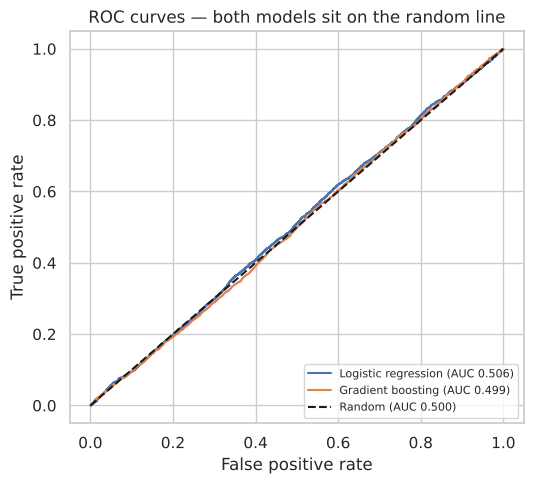

In [37]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y, p)
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Random (AUC 0.500)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves — both models sit on the random line")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("figures/roc_baseline_models.png", dpi=150)
plt.show()

### Step 9 findings

| Model | ROC-AUC | PR-AUC |
|---|---|---|
| Logistic regression | 0.506 | 0.050 |
| Gradient boosting | 0.499 | 0.049 |
| Logistic regression on **shuffled** labels | 0.496 | 0.049 |
| Random guessing | 0.500 | 0.049 |

- Both models score the same as random guessing, **and the same as a model trained on deliberately shuffled labels**.
- Gradient boosting can learn interactions (e.g. Online Purchase × Unknown device), so this also rules out the idea that fraud hides in *combinations* of columns.
- This is the strongest single confirmation of Steps 4–8: the available columns contain **no usable fraud signal**.

## Step 10 — Final conclusion

**1. No column predicts fraud.** Every segment sits at ~5% fraud. The few "significant" gaps (Chicago, Seattle, unknown device) disappear under multiple-testing correction, and Step 8 shows they are what chance produces when you pick the most extreme group. Two models score AUC ≈ 0.50.

**2. The dataset is almost certainly synthetic.** Several facts are very unlikely in real transaction data:
- `Previous_Fraudulent_Transactions` has **zero** relationship with fraud (4.70% at 0 vs 4.80% at 4). In real data, past fraud is one of the strongest predictors.
- Missing values are almost exactly 5% in each of five columns, and categories are nearly equal in size (e.g. 8 cities at ~6,000 each).
- Fraud labels behave like independent coin flips at 4.92%, even per user.

The likely explanation is that the labels were generated randomly, independent of the features. That is a finding about the data, not a failure of the analysis.

**3. Recommendations.**
- Do **not** build fraud rules on location, device, payment method, amount, hour or account age from this data. They would add cost and customer friction without catching fraud.
- If this were a real system: collect stronger signals (device fingerprint, IP / geo-velocity, merchant, time since last transaction, amount vs the user's own history) and verify how the `Fraudulent` label is created.
- Keep monitoring transactions with no device recorded (5.6% vs 4.9%) as a hypothesis only.
- To practise fraud modelling, use a dataset with real signal (e.g. the public credit-card fraud dataset) and reuse this notebook's pipeline.